In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
!ls ./train_code/

colossalai			       train2.log
configs				       train3.log
datacache			       train_gpu.py
exp0417_3D_geometry_vae_releaseV1      train.log
exp0417_3D_geometry_vae_releaseV1_ddp  train_npu_col_asyncfps.py
exp_result			       train_npu_col.py
extra-info			       train_npu_ddp.sh
gen_fps_v2.py			       train_npu_new_metric.py
kernel_meta			       train_npu_single.py
opensora_local			       util.py
profiling			       val_npu.py
__pycache__			       val_npu.sh
src


In [3]:
this_dir = './train_code/train2.log'
f = open(this_dir, 'r').readlines()

In [4]:
f[:5]

['[2025-07-08 18:22:45,242] torch.distributed.run: [WARNING] \n',
 '[2025-07-08 18:22:45,242] torch.distributed.run: [WARNING] *****************************************\n',
 '[2025-07-08 18:22:45,242] torch.distributed.run: [WARNING] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. \n',
 '[2025-07-08 18:22:45,242] torch.distributed.run: [WARNING] *****************************************\n',
 '/home/ma-user/anaconda3/envs/PyTorch-2.1.0/lib/python3.9/site-packages/torch_npu/contrib/transfer_to_npu.py:299: ImportWarning: \n']

In [5]:
res_str = []
for l in f:
    if l.strip().startswith('*****Rank'):
        res_str.append(l.strip())

In [9]:
time_dict = {
    f'Rank{rank}':[] for rank in range(4)
}
time_dict

{'Rank0': [], 'Rank1': [], 'Rank2': [], 'Rank3': []}

In [10]:
for t in res_str:
    rank = t.split()[1][0]
    time_dict['Rank'+rank].append(float(t.split()[4]))
time_dict

{'Rank0': [1.6231,
  9.5603,
  0.761,
  3.0173,
  9.198,
  0.7319,
  1.405,
  10.0246,
  1.5361,
  2.2526,
  8.5956,
  9.2841,
  1.618,
  0.633,
  0.5092,
  9.1403,
  1.6449,
  1.2207,
  0.9349,
  2.0072,
  1.1858,
  1.1092,
  9.2314,
  2.5044,
  1.4707,
  0.5003,
  0.8999,
  0.8992,
  1.7418,
  1.3932,
  1.5373,
  0.9058,
  1.3893,
  2.8997,
  1.5376,
  0.6354,
  1.9927,
  0.2233,
  0.7794,
  1.0118,
  0.9445,
  1.4626,
  0.6943,
  1.0398,
  0.3855,
  2.7883,
  0.9602,
  0.9878,
  1.0938,
  1.5269,
  0.5459,
  0.4012,
  0.9953,
  0.6141,
  1.3774,
  0.9817,
  1.2041,
  1.0778,
  1.1674,
  0.989,
  0.9262,
  0.8146,
  0.8895,
  0.6553,
  0.9022,
  0.5463,
  0.4718,
  0.8814,
  0.8041,
  0.7717,
  0.4215,
  0.623,
  0.6092,
  0.8326,
  0.7594,
  0.5012,
  0.9185,
  0.8978,
  0.815,
  0.7579,
  0.5093,
  1.0775,
  0.7619,
  0.5288,
  0.9475,
  0.4696,
  0.7763,
  0.4352,
  0.5662,
  0.3591,
  0.9548,
  1.1126,
  0.3334,
  0.6527,
  0.895,
  0.3911,
  0.3057,
  0.4919,
  0.884,
  0.4874,


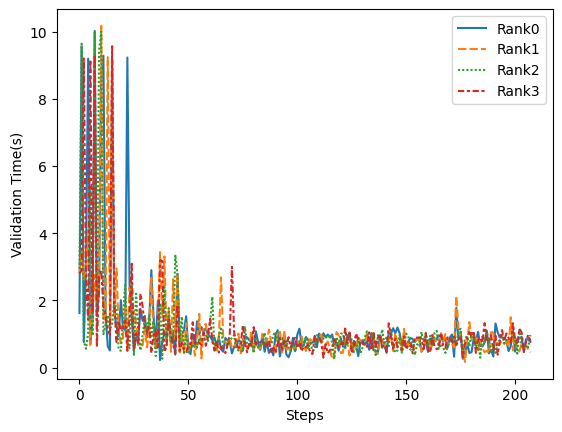

In [25]:
ax = sns.lineplot(time_dict)
plt.xlabel('Steps')
plt.ylabel('Validation Time(s)')
plt.savefig('validation_time.png')

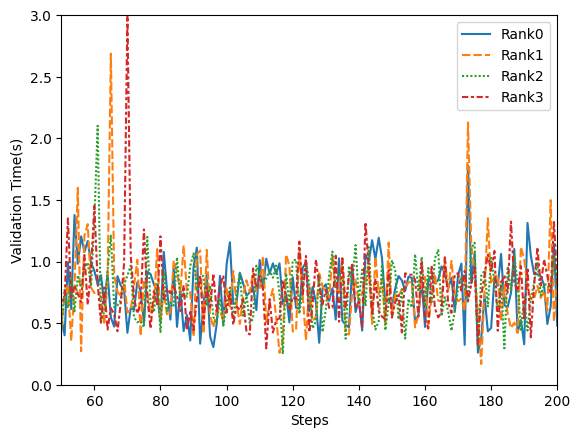

In [24]:
ax = sns.lineplot(time_dict)
plt.xlabel('Steps')
plt.ylabel('Validation Time(s)')
plt.xlim(50, 200)
plt.ylim(0,3)
plt.savefig('validation_time_mid.png')

In [1]:
a = [1,2,2,2,2,3,3,4,5,5]

In [6]:
def bisearch_right(a, target):
    l, r = 0, len(a)-1
    while l < r:
        mid = (l+r+1) // 2
        
        if a[mid] > target:
            r = mid - 1
        else:
            l = mid
    return l

x = bisearch_right(a, 2)
print(x)

4


In [7]:
import random

def find_kth_largest(nums, k):
    def partition(left, right, pivot_idx):
        pivot = nums[pivot_idx]
        # 将基准值交换到最右
        nums[pivot_idx], nums[right] = nums[right], nums[pivot_idx]
        store_idx = left
        for i in range(left, right):
            
            if nums[i] > pivot:  # 注意：这里是找第K大，所以用 > 降序分区
                nums[store_idx], nums[i] = nums[i], nums[store_idx]
                store_idx += 1
            
        # 将基准值放到正确位置
        nums[right], nums[store_idx] = nums[store_idx], nums[right]
        return store_idx

    left, right = 0, len(nums) - 1
    print(nums)
    while True:
        # 随机选择基准值索引（避免最坏情况）
        pivot_idx = random.randint(left, right)
        true_idx = partition(left, right, pivot_idx)
        print(nums)
        if true_idx == k - 1:
            return nums[true_idx]
        elif true_idx < k - 1:
            left = true_idx + 1  # 目标在右半部分
        else:
            right = true_idx - 1  # 目标在左半部分

# 测试
nums = [3, 2, 1, 5, 6, 4]
k = 2
print(find_kth_largest(nums, k))  # 输出: 5（第2大的元素是5）

[3, 2, 1, 5, 6, 4]
[6, 2, 1, 5, 4, 3]
[6, 2, 3, 5, 4, 1]
[6, 5, 3, 4, 2, 1]
5
